# **Solución Práctica 4**

In [3]:
import os, sys, subprocess
from pathlib import Path
import cv2, re, json, random, shutil, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from collections import Counter, defaultdict

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/VC_P4")
    WORK = Path("/content/work")
else:
    BASE = Path(".")
    WORK = Path("work")

WORK.mkdir(parents=True, exist_ok=True)
os.chdir(BASE)
print("Carpeta de trabajo:", Path.cwd())
print("Contenido:", sorted(p.name for p in Path.cwd().iterdir())[:20])


Mounted at /content/drive
Carpeta de trabajo: /content/drive/MyDrive/VC_P4
Contenido: ['C0142.MP4', 'VC_P4.ipynb', 'dataset_manifiesto.csv', 'imagenes', 'ocr_dataset', 'resultado.csv', 'resultado.mp4', 'resultados', 'runs', 'yolo11n.pt']


In [4]:
# instalación de librerías
paquetes = ["ultralytics", "kagglehub", "easyocr", "transformers", "accelerate", "pandas", "matplotlib"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *paquetes], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'ultralytics', 'kagglehub', 'easyocr', 'transformers', 'accelerate', 'pandas', 'matplotlib'], returncode=0)

In [5]:
from ultralytics import YOLO

USA_GPU = torch.cuda.is_available()
DEVICE = 0 if USA_GPU else "cpu"

try:
    import psutil
    print("RAM         :", round(psutil.virtual_memory().total / 1e9, 1), "GB")
except ImportError:
    pass

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
RAM         : 13.6 GB


In [7]:
# entradas
VIDEO = BASE / "C0142.MP4"
DIR_PROPIAS = BASE / "imagenes" # fotos propias
DIR_ANOT_PROPIAS = BASE / "labels" # un .json (labelme/rectangle) o .txt (YOLO) por foto, mismo nombre
RATIOS_PROPIAS = (0.6, 0.2, 0.2) # train/val/test (el test son SÓLO fotos mías)

# dataset de kaggle
KAGGLE_SLUG = "fareselmenshawii/license-plate-dataset"
DIR_KAGGLE = BASE / "kaggle_raw"
N_KAGGLE_TRAIN = 1500
N_KAGGLE_VAL = 300
N_KAGGLE_TEST = 0

# entrenamiento
DATASET = WORK / "dataset"
YAML = WORK / "dataset.yaml"
SEED = 42
IMGSZ = 640
EPOCHS = 40
BATCH = 16 if USA_GPU else 4

# detector general coco
MODELO_GENERAL = "yolo11n.pt"
CLASES = {0: "persona", 1: "bicicleta", 2: "coche", 3: "moto", 5: "autobus", 7: "camion"}
CLASE_PERSONA = 0
VEHICULOS = {1, 2, 3, 5, 7}

random.seed(SEED)
(BASE / "resultados").mkdir(exist_ok=True)

In [8]:
DESCARGAR = True

if DESCARGAR:
    import kagglehub
    DIR_KAGGLE = Path(kagglehub.dataset_download(KAGGLE_SLUG))

print("Dataset en:", DIR_KAGGLE)
for p in sorted(DIR_KAGGLE.rglob("*"))[:12]:
    print("  ", p.relative_to(DIR_KAGGLE))

100%|██████████| 1.54G/1.54G [01:23<00:00, 19.9MB/s]

Extracting files...


Dataset en: /root/.cache/kagglehub/datasets/fareselmenshawii/license-plate-dataset/versions/1
   images
   images/train
   images/train/00009e5b390986a0.jpg
   images/train/000228608388803f.jpg
   images/train/00043e7c5c4c025a.jpg
   images/train/0005ea10e0e14db1.jpg
   images/train/0006dc0977056410.jpg
   images/train/00071c51c8e92a68.jpg
   images/train/00072b81abc72d21.jpg
   images/train/000812dcf304a8e7.jpg
   images/train/000883b46adeca7e.jpg
   images/train/0009c4ddcaab18d3.jpg


In [9]:
EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def split_de(ruta, raiz):
    partes = [p.lower() for p in ruta.relative_to(raiz).parts]
    for clave, nombre in (("train", "train"), ("val", "val"), ("valid", "val"), ("test", "test")):
        if clave in partes:
            return nombre
    return None

def pares_kaggle(raiz):
    # {split: [(imagen, etiqueta.txt)]}, emparejando por nombre dentro de cada split
    raiz = Path(raiz)
    etiquetas = {}
    for t in raiz.rglob("*.txt"):
        if t.name.lower() in {"classes.txt", "labels.txt"}:
            continue
        etiquetas[(split_de(t, raiz), t.stem)] = t
    pares = defaultdict(list)
    for im in raiz.rglob("*"):
        if im.suffix.lower() in EXT:
            s = split_de(im, raiz)
            lbl = etiquetas.get((s, im.stem))
            if lbl is not None:
                pares[s].append((im, lbl))
    return pares

def _fmt(xc, yc, w, h):
    c = lambda v: min(max(v, 0.0), 1.0)
    return f"0 {c(xc):.6f} {c(yc):.6f} {c(w):.6f} {c(h):.6f}"

def lineas_yolo(txt):
    # .txt YOLO -> cajas de clase 0
    salida = []
    for linea in Path(txt).read_text().splitlines():
        t = linea.split()
        if len(t) < 5:
            continue
        try:
            v = [float(x) for x in t[1:]]
        except ValueError:
            continue
        if len(v) in (4, 5):
            xc, yc, w, h = v[:4]
        elif len(v) % 2 == 0:
            xs, ys = v[0::2], v[1::2]
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
            xc, yc, w, h = (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1
        else:
            continue
        salida.append(_fmt(xc, yc, w, h))
    return salida

def lineas_propias(json_path, W, H):
    datos = json.load(open(json_path, encoding="utf-8"))
    salida = []
    if isinstance(datos, dict) and "shapes" in datos:
        for s in datos["shapes"]:
            xs = [p[0] for p in s["points"]]
            ys = [p[1] for p in s["points"]]
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
            salida.append(_fmt((x1 + x2) / 2 / W, (y1 + y2) / 2 / H, (x2 - x1) / W, (y2 - y1) / H))
    else:
        for a in datos:
            xc, yc, w, h = map(float, a["rectangle"])
            if max(xc, yc, w, h) > 1.5:
                xc, w, yc, h = xc / W, w / W, yc / H, h / H
            salida.append(_fmt(xc, yc, w, h))
    return salida

def escribir_par(img_path, lineas, split, origen, manifiesto):
    nombre = f"{origen}_{img_path.name}"
    (DATASET / split / "images").mkdir(parents=True, exist_ok=True)
    (DATASET / split / "labels").mkdir(parents=True, exist_ok=True)
    shutil.copy2(img_path, DATASET / split / "images" / nombre)
    (DATASET / split / "labels" / (Path(nombre).stem + ".txt")).write_text("\n".join(lineas))
    manifiesto.append({"split": split, "origen": origen, "archivo": nombre})

def buscar_anotacion(img_path):
    # busca el .json o .txt de una foto en labels/ o junto a la propia foto
    for carpeta in (DIR_ANOT_PROPIAS, DIR_PROPIAS):
        for ext in (".json", ".txt"):
            p = carpeta / (img_path.stem + ext)
            if p.exists():
                return p
    return None

def anotacion_de(img_path, W, H):
    p = buscar_anotacion(img_path)
    if p is None:
        return None
    return lineas_propias(p, W, H) if p.suffix == ".json" else lineas_yolo(p)

def todas_las_fotos():
    return sorted(p for p in DIR_PROPIAS.iterdir() if p.suffix.lower() in EXT) if DIR_PROPIAS.exists() else []

def fotos_propias():
    # fotos propias que tienen anotación
    return [p for p in todas_las_fotos() if buscar_anotacion(p) is not None]

In [10]:
if DATASET.exists():
    shutil.rmtree(DATASET)
manifiesto = []

# subconjunto de kaggle
pares = pares_kaggle(DIR_KAGGLE)
print("Splits encontrados en Kaggle:", {k: len(v) for k, v in pares.items()})

if not any(pares.get(s) for s in ("train", "val")) and pares.get(None):
    lista = pares[None][:]
    random.shuffle(lista)
    corte = int(len(lista) * 0.8)
    pares["train"], pares["val"] = lista[:corte], lista[corte:]

for split, n in (("train", N_KAGGLE_TRAIN), ("val", N_KAGGLE_VAL), ("test", N_KAGGLE_TEST)):
    pool = pares.get(split, [])
    if n == 0 or not pool:
        continue
    usadas = 0
    for im, lb in random.sample(pool, len(pool)):
        if usadas >= n:
            break
        lineas = lineas_yolo(lb)
        if lineas:
            escribir_par(im, lineas, split, "kaggle", manifiesto)
            usadas += 1

# mis fotos
propias = fotos_propias()
random.shuffle(propias)
n = len(propias)
a = int(n * RATIOS_PROPIAS[0])
b = a + int(n * RATIOS_PROPIAS[1])
for split, lista in {"train": propias[:a], "val": propias[a:b], "test": propias[b:]}.items():
    for img in lista:
        H, W = cv2.imread(str(img)).shape[:2] # cv2 aplica la orientación EXIF
        lineas = anotacion_de(img, W, H)
        if lineas:
            escribir_par(img, lineas, split, "propia", manifiesto)
if not propias:
    print("AVISO: no hay fotos propias anotadas por lo que se entrena sólo con Kaggle (y no habrá split de test propio).")

# dataset.yaml + manifiesto
YAML.write_text(
    f"path: {DATASET.resolve().as_posix()}\n"
    "train: train/images\nval: val/images\ntest: test/images\n"
    "nc: 1\nnames:\n  0: matricula\n"
)
man = pd.DataFrame(manifiesto)
man.to_csv(BASE / "dataset_manifiesto.csv", index=False)
print(man.groupby(["split", "origen"]).size().unstack(fill_value=0))

Splits encontrados en Kaggle: {'train': 4295, 'val': 1073}
AVISO: no hay fotos propias anotadas por lo que se entrena sólo con Kaggle (y no habrá split de test propio).
origen  kaggle
split         
train     1500
val        300


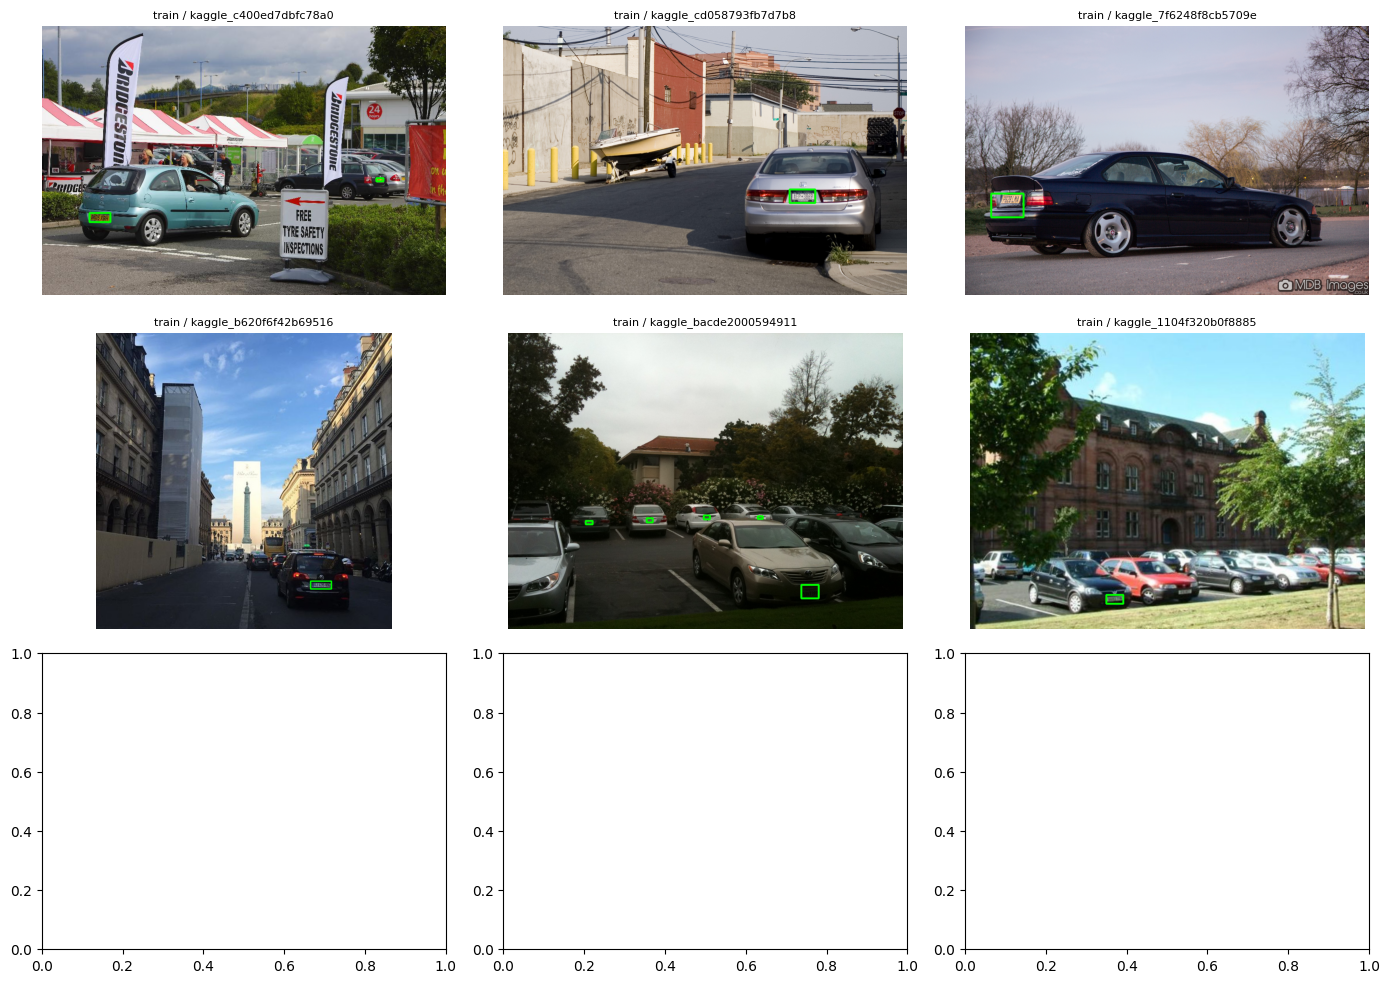

In [11]:
muestras = random.sample(sorted((DATASET / "train" / "images").iterdir()), 6)
if (DATASET / "test" / "images").exists():
    muestras += sorted((DATASET / "test" / "images").iterdir())[:3]

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, img_path in zip(axes.ravel(), muestras):
    im = cv2.imread(str(img_path))
    H, W = im.shape[:2]
    lbl = DATASET / img_path.parent.parent.name / "labels" / (img_path.stem + ".txt")
    for linea in lbl.read_text().splitlines():
        _, xc, yc, w, h = map(float, linea.split())
        cv2.rectangle(im, (int((xc - w / 2) * W), int((yc - h / 2) * H)),
                      (int((xc + w / 2) * W), int((yc + h / 2) * H)), (0, 255, 0), max(2, W // 250))
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{img_path.parent.parent.name} / {img_path.name[:22]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig(BASE / "resultados" / "muestras_dataset.png", dpi=110)
plt.show()

In [12]:
ENTRENAR = True

def ultimo_entreno():
    candidatos = list((BASE / "runs").rglob("results.csv"))
    if not candidatos:
        raise FileNotFoundError("No hay entrenamientos en runs/.")
    return max(candidatos, key=lambda p: p.stat().st_mtime).parent

if ENTRENAR:
    modelo = YOLO("yolo11n.pt")
    modelo.train(
        data=str(YAML),
        epochs=EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH,
        device=DEVICE,
        patience=15,
        seed=SEED,
        workers=2,
        project=str(BASE / "runs"),
        name="detector_matriculas",
        exist_ok=False,
    )

RUN_DIR = ultimo_entreno()
PESOS_MATRICULAS = str(RUN_DIR / "weights" / "best.pt")
print("Entrenamiento usado:", RUN_DIR)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=detector_matriculas-2, nbs=64, nms=None, opset=None, optimize

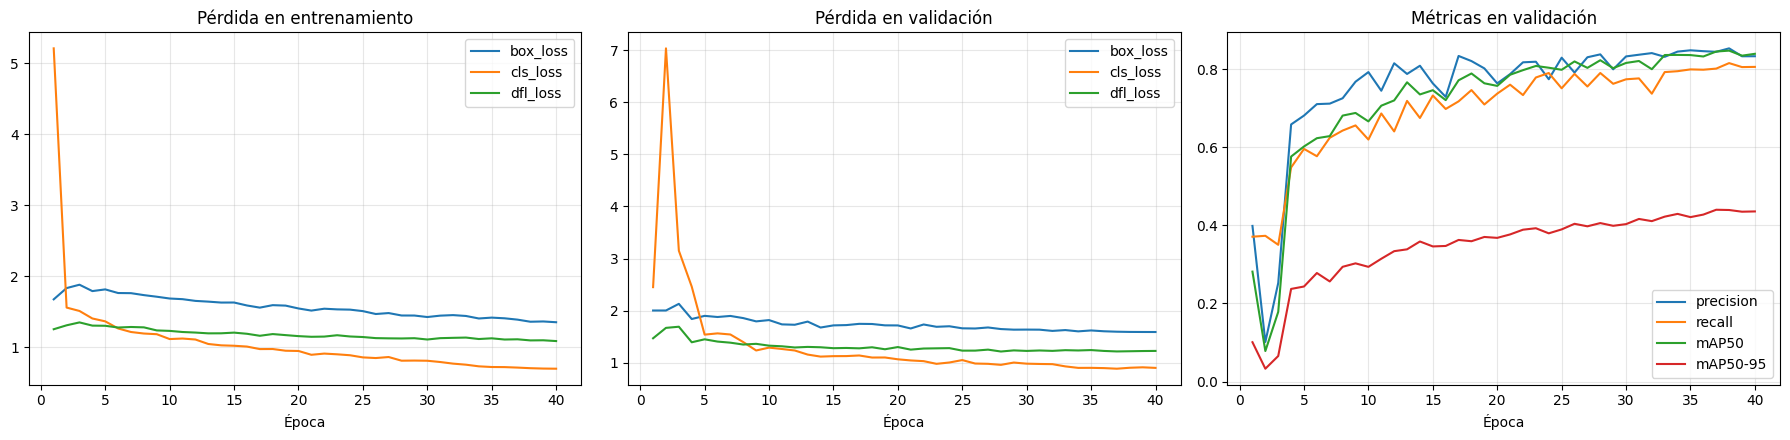

Mejor época: 37 | P=0.845 R=0.802 mAP50=0.845 mAP50-95=0.440


In [13]:
res = pd.read_csv(RUN_DIR / "results.csv")
res.columns = res.columns.str.strip()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for p in ["box_loss", "cls_loss", "dfl_loss"]:
    axes[0].plot(res["epoch"], res["train/" + p], label=p)
    axes[1].plot(res["epoch"], res["val/" + p], label=p)
axes[0].set_title("Pérdida en entrenamiento")
axes[1].set_title("Pérdida en validación")
for m in ["precision", "recall", "mAP50", "mAP50-95"]:
    axes[2].plot(res["epoch"], res["metrics/" + m + "(B)"], label=m)
axes[2].set_title("Métricas en validación")
for ax in axes:
    ax.set_xlabel("Época"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout()
plt.savefig(BASE / "resultados" / "entrenamiento.png", dpi=120)
plt.show()

mejor = res.loc[res["metrics/mAP50-95(B)"].idxmax()]
print(f"Mejor época: {int(mejor['epoch'])} | P={mejor['metrics/precision(B)']:.3f} "
      f"R={mejor['metrics/recall(B)']:.3f} mAP50={mejor['metrics/mAP50(B)']:.3f} "
      f"mAP50-95={mejor['metrics/mAP50-95(B)']:.3f}")

In [14]:
modelo_mat = YOLO(PESOS_MATRICULAS)
for split in ("val", "test"):
    carpeta = DATASET / split / "images"
    if not carpeta.exists() or not any(carpeta.iterdir()):
        continue
    m = modelo_mat.val(data=str(YAML), split=split, imgsz=IMGSZ, conf=0.25, device=DEVICE, plots=(split == "test"))
    print(f"[{split}] P={m.box.mp:.3f}  R={m.box.mr:.3f}  mAP50={m.box.map50:.3f}  mAP50-95={m.box.map:.3f}")

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3193.0±1023.0 MB/s, size: 245.9 KB)
val: Scanning /content/work/dataset/val/labels.cache... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 74.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 4.9it/s 3.8s
                   all        300        434      0.845      0.806      0.789      0.412
Speed: 1.3ms preprocess, 3.9ms inference, 0.0ms loss, 2.1ms postprocess per image
[val] P=0.845  R=0.806  mAP50=0.789  mAP50-95=0.412


In [15]:
OCR_DIR = BASE / "ocr_dataset"
CSV_TEXTO = OCR_DIR / "matriculas_texto.csv"
MARGEN_RECORTE = 0.10 # se amplía un 10 % la caja para no cortar caracteres

USAR_DETECTOR_SI_NO_HAY_ANOTACION = True # si una foto no tiene anotación, se recorta con el detector entrenado

def generar_recortes():
    (OCR_DIR / "crops").mkdir(parents=True, exist_ok=True)
    det = None
    n_anot = n_det = 0
    sin_recorte = []
    for img in todas_las_fotos():
        im = cv2.imread(str(img))
        H, W = im.shape[:2]
        cajas, origen = [], None
        lineas = anotacion_de(img, W, H)
        if lineas:
            origen = "anot"
            for linea in lineas:
                _, xc, yc, w, h = map(float, linea.split())
                cajas.append((xc, yc, w, h))
        elif USAR_DETECTOR_SI_NO_HAY_ANOTACION:
            origen = "det"
            if det is None:
                det = YOLO(PESOS_MATRICULAS)
            r = det.predict(im, imgsz=IMGSZ, conf=0.25, device=DEVICE, verbose=False)[0]
            for x1, y1, x2, y2 in r.boxes.xyxy.cpu().tolist():
                cajas.append(((x1 + x2) / 2 / W, (y1 + y2) / 2 / H, (x2 - x1) / W, (y2 - y1) / H))
        guardados = 0
        for k, (xc, yc, w, h) in enumerate(cajas):
            w, h = w * (1 + MARGEN_RECORTE), h * (1 + MARGEN_RECORTE)
            x1, x2 = max(int((xc - w / 2) * W), 0), min(int((xc + w / 2) * W), W)
            y1, y2 = max(int((yc - h / 2) * H), 0), min(int((yc + h / 2) * H), H)
            rec = im[y1:y2, x1:x2]
            if rec.size:
                cv2.imwrite(str(OCR_DIR / "crops" / f"{img.stem}_{k}.png"), rec)
                guardados += 1
        if guardados == 0:
            sin_recorte.append(img.name)
        elif origen == "anot":
            n_anot += guardados
        else:
            n_det += guardados
    print(f"Recortes desde tus anotaciones: {n_anot} | desde el detector: {n_det}")
    if sin_recorte:
        print("Fotos sin ningún recorte (no hay anotación y el detector no encontró matrícula):", sin_recorte)
    return n_anot + n_det

print("Recortes generados:", generar_recortes())

Recortes desde tus anotaciones: 0 | desde el detector: 32
Fotos sin ningún recorte (no hay anotación y el detector no encontró matrícula): ['coche13.jpg']
Recortes generados: 32


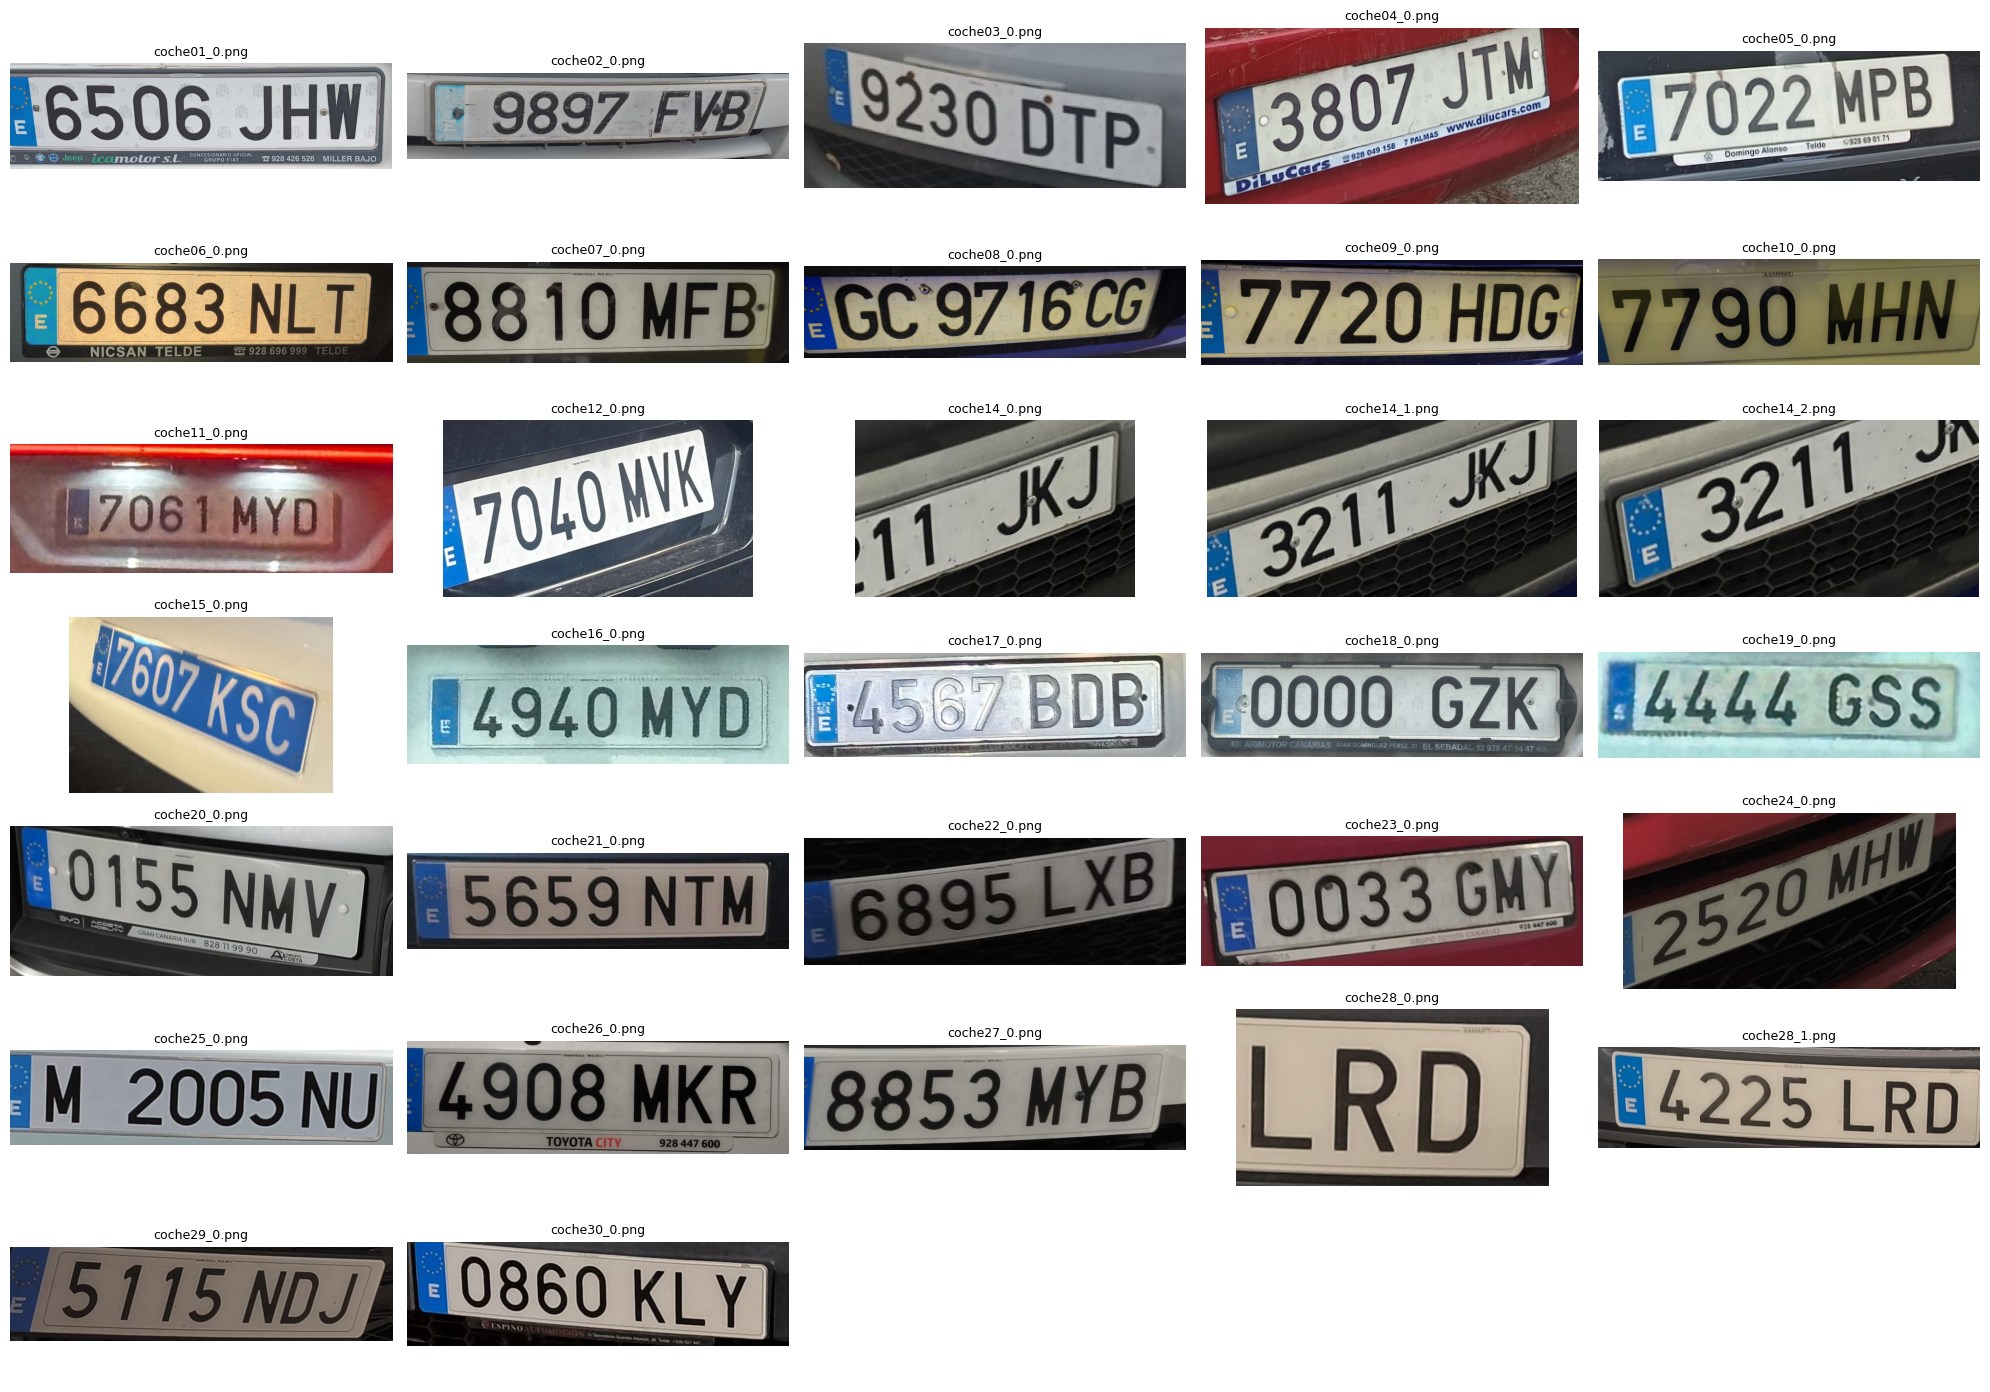

Total etiquetadas: 30


In [16]:
crops = sorted((OCR_DIR / "crops").glob("*.png"))
columnas = 5
filas_fig = -(-len(crops) // columnas)
fig, axes = plt.subplots(filas_fig, columnas, figsize=(4 * columnas, 2 * filas_fig))
axes = np.atleast_1d(axes).ravel()
for ax in axes:
    ax.axis("off")
for ax, p in zip(axes, crops):
    ax.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB))
    ax.set_title(p.name, fontsize=9)
plt.tight_layout()
plt.show()

textos = {
    "coche01_0.png": "6506JHW",
    "coche02_0.png": "9897FVB",
    "coche03_0.png": "9230DTP",
    "coche04_0.png": "3807JTM",
    "coche05_0.png": "7022MPB",
    "coche06_0.png": "6683NLT",
    "coche07_0.png": "8810MFB",
    "coche08_0.png": "GC9716CG",
    "coche09_0.png": "7720HDG",
    "coche10_0.png": "7790MHN",
    "coche11_0.png": "7061MYD",
    "coche12_0.png": "7040MVK",
    "coche14_0.png": "3211JKJ",
    "coche14_1.png": "3211JKJ",
    "coche15_0.png": "7607KSC",
    "coche16_0.png": "4940MYD",
    "coche17_0.png": "4567BDB",
    "coche18_0.png": "0000GZK",
    "coche19_0.png": "4444GSS",
    "coche20_0.png": "0155NMV",
    "coche21_0.png": "5659NTM",
    "coche22_0.png": "6895LXB",
    "coche23_0.png": "0033GMY",
    "coche24_0.png": "2520MHW",
    "coche25_0.png": "M2005NU",
    "coche26_0.png": "4908MKR",
    "coche27_0.png": "8853MYB",
    "coche28_0.png": "4225LRD",
    "coche29_0.png": "5115NDJ",
    "coche30_0.png": "0860KLY",
}

CSV_TEXTO = OCR_DIR / "matriculas_texto.csv"
df_txt = pd.DataFrame([{"recorte": k, "texto_real": re.sub(r"[^A-Z0-9]", "", v.upper())}
                       for k, v in textos.items() if v.strip()])
df_txt.to_csv(CSV_TEXTO, index=False)
print("Total etiquetadas:", len(df_txt))

In [17]:
ALFABETO = "ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
VLM_ID = "HuggingFaceTB/SmolVLM-500M-Instruct"
PROMPT_VLM = "Read the license plate in the image. Answer only with the plate characters, no spaces and no other text."

def normalizar(t):
    return re.sub(r"[^A-Z0-9]", "", str(t).upper())

def levenshtein(a, b):
    if a == b:
        return 0
    if not a or not b:
        return max(len(a), len(b))
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def sync():
    if USA_GPU:
        torch.cuda.synchronize()

def cargar_easyocr():
    import easyocr
    lector = easyocr.Reader(["es", "en"], gpu=USA_GPU, verbose=False)

    def leer(img_bgr):
        return "".join(lector.readtext(img_bgr, detail=0, allowlist=ALFABETO))
    return leer

def cargar_smolvlm():
    from PIL import Image
    from transformers import AutoProcessor
    try:
        from transformers import AutoModelForImageTextToText as AutoVLM
    except ImportError:
        from transformers import AutoModelForVision2Seq as AutoVLM
    dtype = torch.float16 if USA_GPU else torch.float32 # si sale texto raro con fp16, prueba torch.float32
    procesador = AutoProcessor.from_pretrained(VLM_ID)
    modelo_vlm = AutoVLM.from_pretrained(VLM_ID, torch_dtype=dtype).to("cuda" if USA_GPU else "cpu").eval()
    mensajes = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": PROMPT_VLM}]}]
    prompt = procesador.apply_chat_template(mensajes, add_generation_prompt=True)

    def leer(img_bgr):
        pil = Image.fromarray(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
        entrada = procesador(text=prompt, images=[pil], return_tensors="pt").to(modelo_vlm.device, dtype)
        with torch.no_grad():
            salida = modelo_vlm.generate(**entrada, max_new_tokens=16, do_sample=False)
        return procesador.batch_decode(salida, skip_special_tokens=True)[0].split("Assistant:")[-1]
    return leer

CARGADORES = {"easyocr": cargar_easyocr, "smolvlm": cargar_smolvlm}
_MOTORES = {}

def motor(nombre):
    if nombre not in _MOTORES:
        _MOTORES[nombre] = CARGADORES[nombre]()
    return _MOTORES[nombre]

In [18]:
OCR_COMPARAR = ["easyocr", "smolvlm"]
N_CALENTAMIENTO = 3

gt = pd.read_csv(CSV_TEXTO, dtype=str).fillna("")
gt = gt[gt["texto_real"] != ""].reset_index(drop=True)
print("Recortes con texto real:", len(gt), "(se recomienda ≥ 30)")

imagenes = [cv2.imread(str(OCR_DIR / "crops" / r)) for r in gt["recorte"]]
filas = []
for nombre in OCR_COMPARAR:
    leer = motor(nombre)
    for im in imagenes[:N_CALENTAMIENTO]: # calentamiento no se mide
        leer(im)
    for rec, real, im in zip(gt["recorte"], gt["texto_real"], imagenes):
        sync(); t0 = time.perf_counter()
        bruto = leer(im)
        sync(); dt = time.perf_counter() - t0
        pred = normalizar(bruto)
        filas.append({"motor": nombre, "recorte": rec, "texto_real": real, "texto_pred": pred,
                      "acierto": int(pred == real), "cer": levenshtein(real, pred) / max(len(real), 1),
                      "tiempo_s": dt})

comp = pd.DataFrame(filas)
comp.to_csv(BASE / "resultados" / "comparativa_ocr.csv", index=False)

resumen = comp.groupby("motor").agg(
    n=("acierto", "size"),
    acierto_pct=("acierto", lambda s: 100 * s.mean()),
    cer_medio=("cer", "mean"),
    tiempo_medio_ms=("tiempo_s", lambda s: 1000 * s.mean()),
    tiempo_mediano_ms=("tiempo_s", lambda s: 1000 * s.median()),
    tiempo_p95_ms=("tiempo_s", lambda s: 1000 * s.quantile(0.95)),
).round(2)
resumen["img_por_s"] = (1000 / resumen["tiempo_medio_ms"].clip(lower=1e-6)).round(2)
resumen.to_csv(BASE / "resultados" / "resumen_ocr.csv")
print(resumen.to_string())

Recortes con texto real: 30 (se recomienda ≥ 30)


processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.34k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.2k [00:00<?, ?B/s]

... (7 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

          n  acierto_pct  cer_medio  tiempo_medio_ms  tiempo_mediano_ms  tiempo_p95_ms  img_por_s
motor                                                                                            
easyocr  30        26.67       1.50           109.37              83.24         228.09       9.14
smolvlm  30        73.33       0.15           538.28             541.60         670.23       1.86


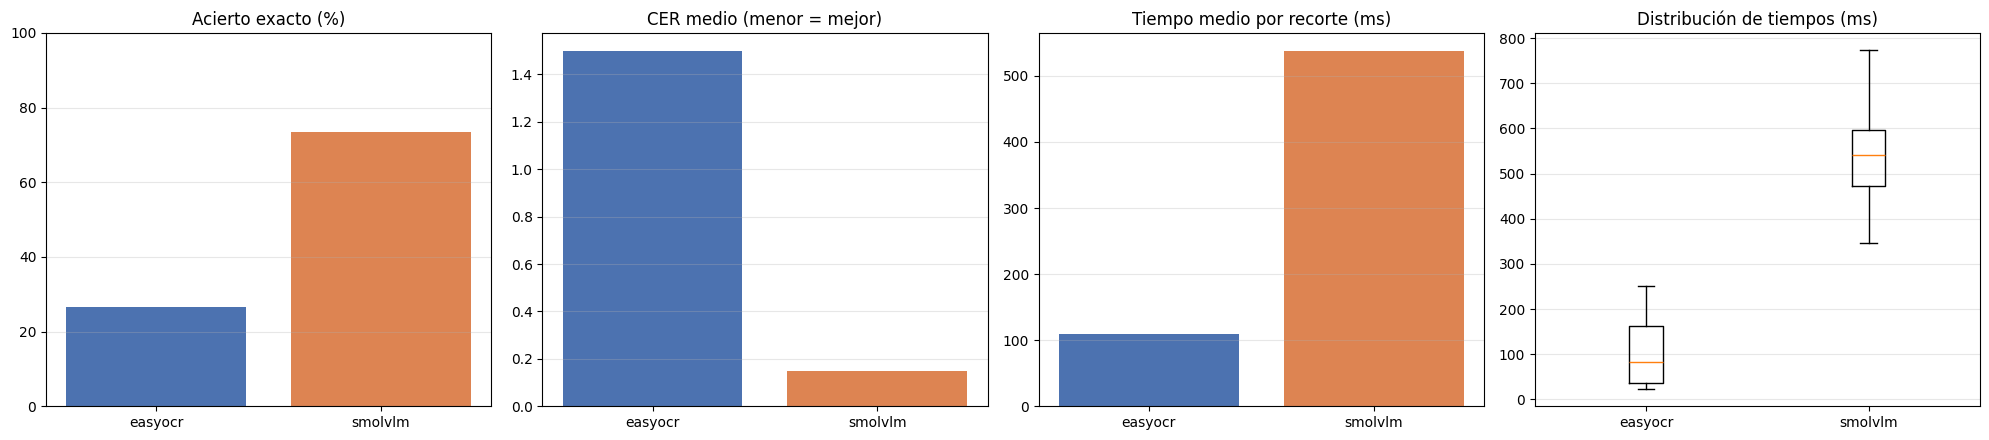


Peores lecturas de easyocr
      recorte texto_real                                                       texto_pred      cer
coche01_0.png    6506JHW E6506JHWCONCESIONARIOUFICIALJEPR0SLGRUPOFIAT0928426526MILLERBAJO 8.142857
coche18_0.png    0000GZK  E0000GZKARIMOTORCANARIASJUANDOMINGUEZPEREZ21ELSEBADAL0928471447 8.000000
coche20_0.png    0155NMV                         EGRANSUR8287199900155NMV942C5SECANAAIAQ6 4.714286
coche04_0.png    3807JTM                                 JTM3807COMWWIDIUA6SAPALMA282DIGS 3.857143
coche06_0.png    6683NLT                                E6683NLTNICSANTELDE928696999TELDE 3.714286

Peores lecturas de smolvlm
      recorte texto_real texto_pred      cer
coche18_0.png    0000GZK        GBZ 0.857143
coche01_0.png    6506JHW        JHW 0.571429
coche14_0.png    3211JKJ        JKJ 0.571429
coche04_0.png    3807JTM        JTM 0.571429
coche14_1.png    3211JKJ        JKJ 0.571429


In [19]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
motores = list(resumen.index)
axes[0].bar(motores, resumen["acierto_pct"], color=["#4c72b0", "#dd8452"][:len(motores)])
axes[0].set_title("Acierto exacto (%)"); axes[0].set_ylim(0, 100)
axes[1].bar(motores, resumen["cer_medio"], color=["#4c72b0", "#dd8452"][:len(motores)])
axes[1].set_title("CER medio (menor = mejor)")
axes[2].bar(motores, resumen["tiempo_medio_ms"], color=["#4c72b0", "#dd8452"][:len(motores)])
axes[2].set_title("Tiempo medio por recorte (ms)")
axes[3].boxplot([1000 * comp.loc[comp["motor"] == m, "tiempo_s"] for m in motores])
axes[3].set_xticks(range(1, len(motores) + 1))
axes[3].set_xticklabels(motores)
axes[3].set_title("Distribución de tiempos (ms)")
for ax in axes:
    ax.grid(alpha=.3, axis="y")
plt.tight_layout()
plt.savefig(BASE / "resultados" / "comparativa_ocr.png", dpi=120)
plt.show()

# errores más claros de cada motor
for m in motores:
    e = comp[(comp["motor"] == m) & (comp["acierto"] == 0)].sort_values("cer", ascending=False).head(5)
    print(f"\nPeores lecturas de {m}")
    print(e[["recorte", "texto_real", "texto_pred", "cer"]].to_string(index=False))

In [21]:
MIN_FRAMES = 15
MIN_DESPL_VEHICULO = 0.10 # proporción del ancho del vídeo
MIN_DESPL_PERSONA = 0.05
ALTO_MIN_VEHICULO = 60
CONF = 0.3
LIMITE = None # p. ej. 300 para pruebas rápidas -> None = vídeo completo
K_RECORTES = 3
OCR_VIDEO = "easyocr" # "easyocr" o "smolvlm"
POSTPROCESO_ES = True # corrige confusiones típicas (O/0, I/1...) en formato 4 cifras + 3 letras

VIDEO_LOCAL = WORK / VIDEO.name
if not VIDEO_LOCAL.exists():
    shutil.copy2(VIDEO, VIDEO_LOCAL) # leer del disco local es mucho más rápido que de Drive

detector = YOLO(MODELO_GENERAL)
det_mat = YOLO(PESOS_MATRICULAS)

cap = cv2.VideoCapture(str(VIDEO_LOCAL))
FPS = cap.get(cv2.CAP_PROP_FPS)
ANCHO = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
ALTO = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

detecciones = []
historial = defaultdict(list)
mejores = defaultdict(list) # id -> [(puntuación, recorte matrícula)]

for n_frame, r in enumerate(detector.track(source=str(VIDEO_LOCAL), stream=True, persist=True, verbose=False,
                                           classes=list(CLASES), conf=CONF, device=DEVICE)):
    if LIMITE and n_frame >= LIMITE:
        break
    if r.boxes.id is None:
        continue
    frame = r.orig_img
    ids = r.boxes.id.int().cpu().tolist()
    clases = r.boxes.cls.int().cpu().tolist()
    confs = r.boxes.conf.cpu().tolist()
    cajas = r.boxes.xyxy.cpu().tolist()

    for tid, cid, conf, caja in zip(ids, clases, confs, cajas):
        x1, y1, x2, y2 = [int(v) for v in caja]
        x1, y1, x2, y2 = max(x1, 0), max(y1, 0), min(x2, ANCHO), min(y2, ALTO)
        historial[tid].append((cid, (x1 + x2) / 2, (y1 + y2) / 2))
        fila = {"fotograma": n_frame, "tipo": cid, "confianza": round(conf, 3), "id": tid,
                "x1": x1, "y1": y1, "x2": x2, "y2": y2, "mat": None}

        if cid in VEHICULOS and cid != 1 and (y2 - y1) >= ALTO_MIN_VEHICULO:
            rm = det_mat.predict(frame[y1:y2, x1:x2], imgsz=IMGSZ, conf=CONF, device=DEVICE, verbose=False)[0]
            if len(rm.boxes) > 0:
                k = int(rm.boxes.conf.argmax())
                p, q, s, t = [int(v) for v in rm.boxes.xyxy[k].tolist()]
                cm = round(float(rm.boxes.conf[k]), 3)
                mx1, my1, mx2, my2 = p + x1, q + y1, s + x1, t + y1
                fila["mat"] = (cm, mx1, my1, mx2, my2)
                rec = frame[my1:my2, mx1:mx2]
                if rec.size:
                    nitidez = cv2.Laplacian(cv2.cvtColor(rec, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var()
                    puntuacion = cm * np.sqrt(rec.shape[0] * rec.shape[1]) * np.log1p(nitidez)
                    mejores[tid].append((puntuacion, rec.copy()))
                    mejores[tid].sort(key=lambda z: -z[0])
                    del mejores[tid][K_RECORTES:]
        detecciones.append(fila)

print("Fotogramas procesados:", n_frame + 1, "| ids distintos sin filtrar:", len(historial))

Fotogramas procesados: 2832 | ids distintos sin filtrar: 59


In [22]:
def clase_mayoritaria(puntos):
    return Counter(c for c, _, _ in puntos).most_common(1)[0][0]

def desplazamiento(puntos):
    centros = np.array([(x, y) for _, x, y in puntos])
    return np.linalg.norm(centros[-5:].mean(axis=0) - centros[:5].mean(axis=0))

def se_cuenta(puntos):
    minimo = MIN_DESPL_PERSONA if clase_mayoritaria(puntos) == CLASE_PERSONA else MIN_DESPL_VEHICULO
    return len(puntos) >= MIN_FRAMES and desplazamiento(puntos) >= minimo * ANCHO

clase_track = {t: clase_mayoritaria(p) for t, p in historial.items()}
contados = {t for t, p in historial.items() if se_cuenta(p)}

conteo = Counter(CLASES[clase_track[t]] for t in contados)
print("Total PERSONAS :", conteo["persona"])
print("Total VEHÍCULOS:", sum(v for k, v in conteo.items() if k != "persona"))
print("Por clase      :", dict(conteo))

Total PERSONAS : 11
Total VEHÍCULOS: 31
Por clase      : {'autobus': 1, 'persona': 11, 'coche': 28, 'bicicleta': 1, 'moto': 1}


Vehículos contados: 30 | con matrícula detectada: 29 | con texto válido: 8
Ancho de los recortes de matrícula en el vídeo (px): mín 36 · mediana 82 · máx 177


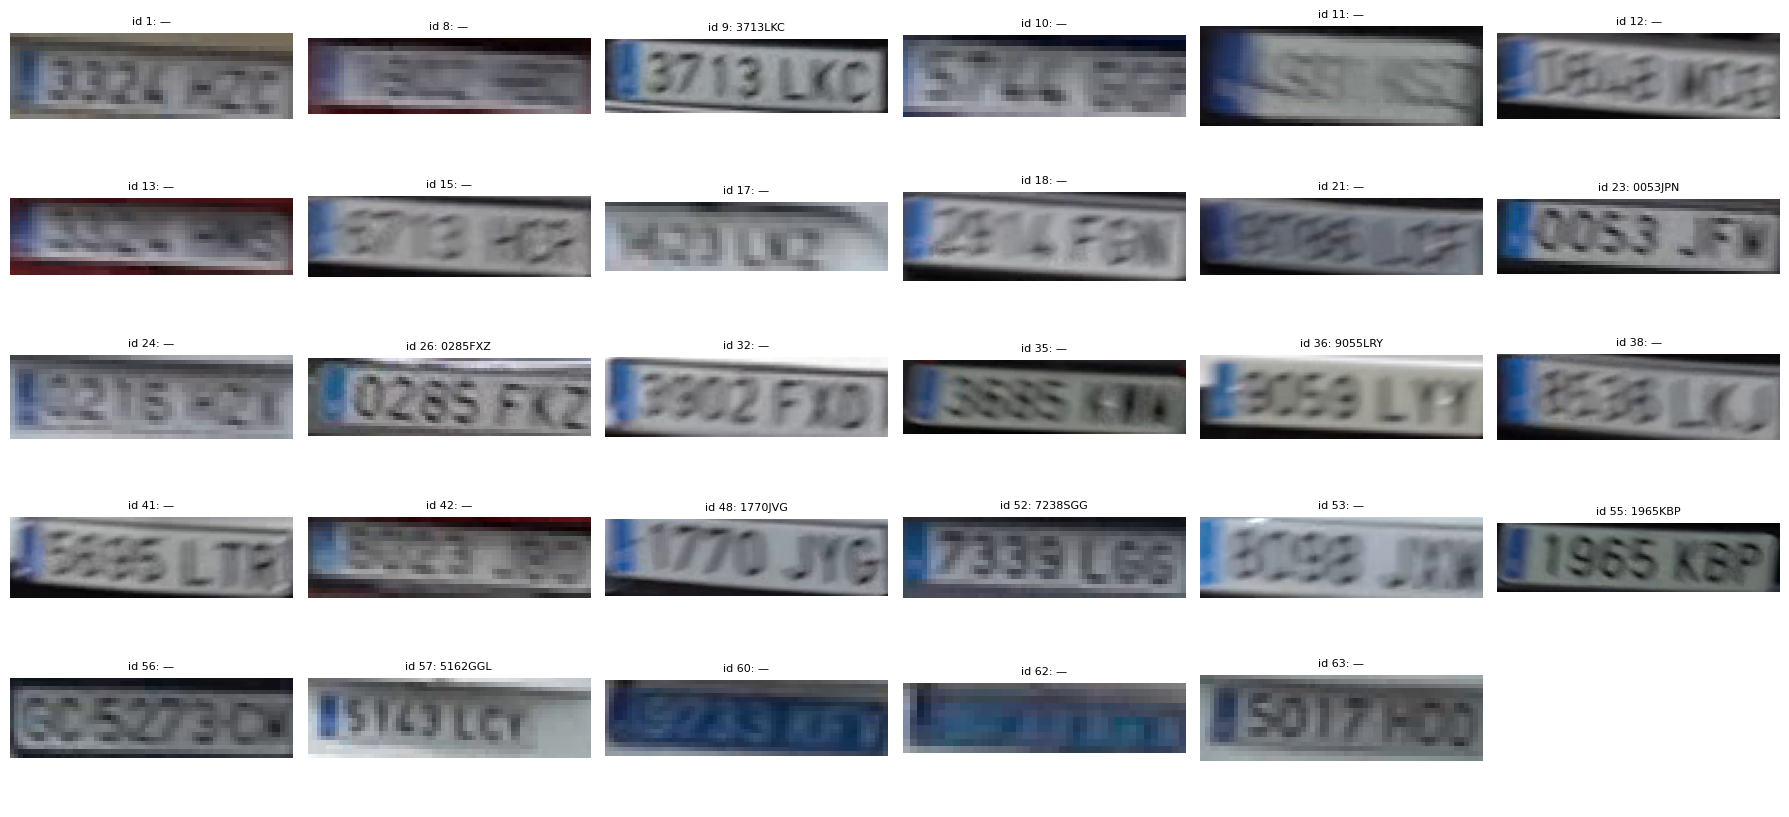

In [23]:
# OCR de las mejores matrículas de cada vehículo contado (SmolVLM + validación de formato)
OCR_VIDEO = "smolvlm" # el que mejor salió en la comparativa
PATRON_NUEVO = re.compile(r"^\d{4}[BCDFGHJKLMNPRSTVWXYZ]{3}$") # 1234ABC
PATRON_ANTIGUO = re.compile(r"^[A-Z]{1,2}\d{4}[A-Z]{1,2}$") # GC1234CG
A_NUM = {"O": "0", "Q": "0", "D": "0", "I": "1", "L": "1", "Z": "2", "S": "5", "G": "6", "T": "7", "B": "8"}
A_LET = {"0": "D", "1": "L", "2": "Z", "5": "S", "6": "G", "8": "B"}


def corregir_es(t):
    # corrige confusiones
    if len(t) != 7:
        return t
    c = "".join(A_NUM.get(x, x) for x in t[:4]) + "".join(A_LET.get(x, x) for x in t[4:])
    return c if PATRON_NUEVO.match(c) else t

def es_valida(t):
    return bool(PATRON_NUEVO.match(t) or PATRON_ANTIGUO.match(t))

def ampliar(rec, ancho_min=240):
    h, w = rec.shape[:2]
    if w < ancho_min:
        rec = cv2.resize(rec, None, fx=ancho_min / w, fy=ancho_min / w, interpolation=cv2.INTER_CUBIC)
    return rec

leer_matricula = motor(OCR_VIDEO)
texto_id, lecturas_id = {}, {}
for tid in contados:
    lecturas = []
    for _, rec in mejores.get(tid, []):
        t = corregir_es(normalizar(leer_matricula(ampliar(rec))))
        if t:
            lecturas.append(t)
    lecturas_id[tid] = lecturas
    validas = [t for t in lecturas if es_valida(t)] # sólo se acepta un texto con formato de matrícula
    if validas:
        texto_id[tid] = Counter(validas).most_common(1)[0][0]

vehiculos_c = [t for t in contados if clase_track[t] in VEHICULOS and clase_track[t] != 1]
con_matricula = [t for t in vehiculos_c if mejores.get(t)]
print(f"Vehículos contados: {len(vehiculos_c)} | con matrícula detectada: {len(con_matricula)} | con texto válido: {len(texto_id)}")
if con_matricula:
    anchos = [rec.shape[1] for t in con_matricula for _, rec in mejores[t]]
    print(f"Ancho de los recortes de matrícula en el vídeo (px): mín {min(anchos)} · mediana {int(np.median(anchos))} · máx {max(anchos)}")

vis = [(t, mejores[t][0][1]) for t in con_matricula]
if vis:
    cols = 6
    filas_fig = -(-len(vis) // cols)
    fig, axes = plt.subplots(filas_fig, cols, figsize=(3 * cols, 1.7 * filas_fig))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (t, rec) in zip(axes, vis):
        ax.imshow(cv2.cvtColor(rec, cv2.COLOR_BGR2RGB))
        ax.set_title(f"id {t}: {texto_id.get(t, '—')}", fontsize=8)
    plt.tight_layout()
    plt.savefig(BASE / "resultados" / "matriculas_video.png", dpi=110)
    plt.show()

In [24]:
# csv
filas = []
for d in detecciones:
    if d["id"] not in contados:
        continue
    if d["mat"] is not None:
        cm, mx1, my1, mx2, my2 = d["mat"]
        hay, texto = 1, texto_id.get(d["id"], "")
    else:
        cm = mx1 = my1 = mx2 = my2 = ""
        hay, texto = 0, ""
    filas.append({
        "fotograma": d["fotograma"],
        "tipo_objeto": CLASES[clase_track[d["id"]]],
        "confianza": d["confianza"],
        "identificador_tracking": d["id"],
        "x1": d["x1"], "y1": d["y1"], "x2": d["x2"], "y2": d["y2"],
        "matricula_en_su_caso": hay, "confianza_matricula": cm,
        "mx1": mx1, "my1": my1, "mx2": mx2, "my2": my2,
        "texto_matricula": texto,
    })
pd.DataFrame(filas).to_csv(BASE / "resultado.csv", index=False)
print("resultado.csv:", len(filas), "filas")

# vídeo (se escribe en disco local y luego se copia a drive)
por_frame = defaultdict(list)
for d in detecciones:
    if d["id"] in contados:
        por_frame[d["fotograma"]].append(d)


def etiqueta(img, texto, x, y, fondo, color_texto=(255, 255, 255), escala=0.5):
    (tw, th), base = cv2.getTextSize(texto, cv2.FONT_HERSHEY_SIMPLEX, escala, 1)
    x, y = max(0, x), max(th + 4, y)
    cv2.rectangle(img, (x, y - th - 4), (x + tw + 4, y + base - 2), fondo, -1)
    cv2.putText(img, texto, (x + 2, y - 3), cv2.FONT_HERSHEY_SIMPLEX, escala, color_texto, 1, cv2.LINE_AA)


SALIDA_LOCAL = WORK / "resultado.mp4"
cap = cv2.VideoCapture(str(VIDEO_LOCAL))
out = cv2.VideoWriter(str(SALIDA_LOCAL), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (ANCHO, ALTO))
vistos, n = set(), 0
while True:
    ok, frame = cap.read()
    if not ok or (LIMITE and n >= LIMITE):
        break
    for d in por_frame[n]:
        es_persona = clase_track[d["id"]] == CLASE_PERSONA
        color = (0, 200, 0) if es_persona else (255, 140, 0)
        cv2.rectangle(frame, (d["x1"], d["y1"]), (d["x2"], d["y2"]), color, 2)
        etiqueta(frame, f"{CLASES[clase_track[d['id']]]} {d['id']}", d["x1"], d["y1"] - 2, color)
        if d["mat"] is not None:
            _, mx1, my1, mx2, my2 = d["mat"]
            cv2.rectangle(frame, (mx1, my1), (mx2, my2), (0, 255, 255), 2)
            if d["id"] in texto_id:
                etiqueta(frame, texto_id[d["id"]], mx1, my1 - 2, (0, 255, 255), color_texto=(0, 0, 0), escala=0.7)
        vistos.add(d["id"])
    acum = Counter(CLASES[clase_track[t]] for t in vistos)
    etiqueta(frame, f"Personas: {acum['persona']}  Vehiculos: {sum(v for k, v in acum.items() if k != 'persona')}",
             10, 30, (0, 0, 0), escala=0.8)
    out.write(frame)
    n += 1
cap.release()
out.release()
shutil.copy2(SALIDA_LOCAL, BASE / "resultado.mp4")
print("resultado.mp4 guardado en", BASE)

resultado.csv: 7347 filas
resultado.mp4 guardado en /content/drive/MyDrive/VC_P4


           hacia la derecha  hacia la izquierda
personas                  9                   2
vehículos                 5                  26


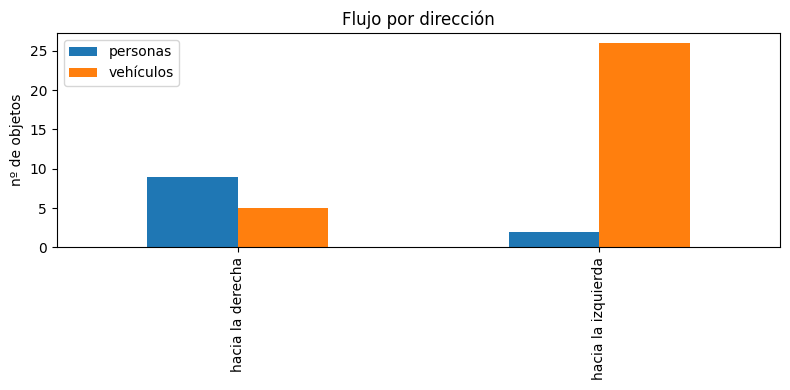

In [25]:
def direccion(puntos):
    c = np.array([(x, y) for _, x, y in puntos])
    dx, dy = c[-5:].mean(axis=0) - c[:5].mean(axis=0)
    if abs(dx) >= abs(dy):
        return "hacia la derecha" if dx > 0 else "hacia la izquierda"
    return "hacia abajo (se acerca)" if dy > 0 else "hacia arriba (se aleja)"


flujo = Counter()
for t in contados:
    grupo = "personas" if clase_track[t] == CLASE_PERSONA else "vehículos"
    flujo[(grupo, direccion(historial[t]))] += 1

if flujo:
    tabla = pd.Series(flujo).unstack(fill_value=0)
    print(tabla)
    tabla.T.plot(kind="bar", figsize=(8, 4), title="Flujo por dirección")
    plt.ylabel("nº de objetos"); plt.tight_layout()
    plt.savefig(BASE / "resultados" / "flujo.png", dpi=120)
    plt.show()